<div align="center">

# UNIVERSIDAD NACIONAL DEL CENTRO DEL PERÚ
## Facultad de Ingeniería de Sistemas

### INGENIERÍA DEL CONOCIMIENTO (ISO56B)
**Evaluación Parcial — Actividad 2**
**Red Neuronal Convolucional sobre Dataset de Imagen Real**

</div>

---

# SECCIÓN A — Presentación

### A.1 Datos del curso

| Campo | Detalle |
|---|---|
| **Curso** | Ingeniería del Conocimiento (ISO56B) |
| **Semestre** | 2026-II |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |
| **Fecha de entrega** | 22 / 10 / 2026 |

### A.2 Integrantes del grupo

| N.º | Apellidos y nombres | Código |
|:-:|---|---|
| 1 | Acevedo Pomayay Jean Pool Thair | 2024200178I |
| 2 | Rouviros Santacroce Eduardo | 2024200204I |
| 3 | Loyola Rodriguez Renzo Styp | 2024200192J |
| 4 | Alfaro Victoria Gino Paoli | 2024200179J |

### A.3 Dataset elegido

| Campo | Detalle |
|---|---|
| **Nombre** | *Pokemon Image Dataset* (autor: lantian773030) |
| **Fuente de las imágenes** | Kaggle — `https://www.kaggle.com/datasets/lantian773030/pokemonclassification` |
| **Contenido** | Imágenes reales y variadas (ilustraciones, capturas, figuras, cartas) de los Pokémon de la generación I, **una carpeta por Pokémon** |
| **Fuente de la etiqueta** | Tipo principal (`type_01`) tomado del Excel `datos_ing_conocimiento.xlsx` de la **Actividad 1**, enlazado por el **nombre** del Pokémon. Si el Excel no está disponible de forma local, se usa automáticamente la tabla de respaldo con los tipos oficiales de la generación I integrada en el código |
| **Clases usadas** | 5 tipos: Agua, Fuego, Planta, Eléctrico y Psíquico |
| **Tamaño** | La celda B.1 imprime el número exacto de imágenes **únicas** (sin duplicados) y **verifica con un `assert` que sean al menos 1 000**, como exige la consigna |

**Justificación de la elección**
- Son **imágenes reales y heterogéneas** (distintos estilos, fondos, poses y tamaños), no sintéticas, y no se usaron en clase.
- **Conecta con la Actividad 1:** usamos el mismo universo Pokémon y el mismo Excel de tipos, ahora desde las imágenes en lugar de las estadísticas.
- **Elegimos 5 tipos** con suficientes especies e imágenes cada uno. Con los 18 tipos habría clases con 1 o 2 especies (por ejemplo, Hielo o Dragón en la generación I), imposibles de aprender.
- **Calidad de datos:** se descartan archivos que no son imagen (por ejemplo `.svg`) o que no se pueden abrir, y se eliminan **duplicados exactos** (mismo contenido de píxeles) para no contar dos veces la misma imagen.

### A.4 Descripción del problema
El objetivo es entrenar una **red neuronal convolucional (CNN)** que, viendo solo la **imagen** de un Pokémon, prediga su **tipo principal** entre 5 opciones: Agua, Fuego, Planta, Eléctrico o Psíquico. Es un problema de **clasificación multiclase de imágenes**. Las dificultades son: (1) las clases están **desbalanceadas** (en la generación I hay muchas más especies de Agua que de Psíquico); (2) el tipo **no siempre coincide con el color** (Magikarp es de Agua y es rojo); y (3) las imágenes tienen estilos y fondos muy distintos. Con pocos miles de imágenes, el **sobreajuste** es el reto principal.

### A.5 Uso de GPU
Este notebook se ejecuta con **GPU habilitada**: `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4`. La celda de configuración imprime la GPU detectada.

> **Declaración de uso de IA:** se utilizó un asistente de IA generativa como apoyo en la revisión del código y la redacción. Todo el contenido fue revisado, ejecutado de principio a fin y comprendido por los integrantes.

---
# SECCIÓN B — Carga, Exploración y Preprocesamiento

### Configuración: librerías, semilla y GPU

In [1]:
import os, glob, re, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display, Markdown

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, f1_score
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
keras.utils.set_random_seed(SEED)     # fija la semilla de Python, NumPy y TensorFlow
sns.set_theme(style="whitegrid")

print("Versión de TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus if gpus else "NO — activar en Entorno de ejecución → T4 GPU")

Versión de TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### B.1 Carga del dataset
**De dónde salen las imágenes:** la celda intenta descargar el dataset con `kagglehub` (viene instalado en Colab). Si no puede, busca un `.zip` local.

**Cómo se asigna la etiqueta:** cada carpeta tiene el nombre de un Pokémon (`Pikachu/`, `Charmander/`, …). Normalizamos el nombre (minúsculas, sin espacios ni signos: `Mr. Mime` → `mrmime`) y buscamos su `type_01` en el Excel de la Actividad 1 si está disponible; de lo contrario, se usa de forma robusta la tabla de respaldo oficial integrada en el código.

**Preprocesamiento de cada imagen:**
- Las imágenes con transparencia (RGBA) se pegan sobre **fondo blanco** para tener siempre 3 canales (RGB).
- Se llevan a **128 × 128** píxeles **sin deformarlas**: se escala manteniendo la proporción y se completa con blanco (`ImageOps.pad`).
- Se calcula una **huella MD5** de los píxeles para descartar **duplicados exactos**.

In [2]:
# ── 1) Conseguir las imágenes: kagglehub o un .zip local ──
def buscar_raiz(base):
    """Devuelve la carpeta que contiene una subcarpeta por Pokémon (p. ej. .../PokemonData)."""
    for raiz, dirs, _ in os.walk(base):
        if "Pikachu" in dirs and "Charmander" in dirs:
            return raiz
    return None

RAIZ = buscar_raiz(".")
if RAIZ is None:
    try:
        import kagglehub
        RAIZ = buscar_raiz(kagglehub.dataset_download("lantian773030/pokemonclassification"))
    except Exception as e:
        print("No se pudo descargar automáticamente con kagglehub:", e)
if RAIZ is None:
    zips = glob.glob("*.zip")
    for z in zips:
        with zipfile.ZipFile(z) as f:
            f.extractall("dataset_pokemon")
    RAIZ = buscar_raiz("dataset_pokemon")
assert RAIZ is not None, "No se encontró la carpeta con una subcarpeta por Pokémon. Asegúrate de colocar el dataset en el entorno."
print("Carpeta de imágenes encontrada:", RAIZ)

# ── 2) Tipo principal de cada Pokémon ──
CLASES = {"Water": "Agua", "Fire": "Fuego", "Grass": "Planta",
          "Electric": "Eléctrico", "Psychic": "Psíquico"}
NOMBRES_CLASES = list(CLASES.values())
NUM_CLASES = len(CLASES)

def normalizar(nombre):
    return re.sub(r"[^a-z0-9]", "", str(nombre).lower())

# Respaldo robusto: tipo principal oficial de los Pokémon de la generación I de estos 5 tipos
TIPOS_GEN1 = {
    "Water": ["Squirtle", "Wartortle", "Blastoise", "Psyduck", "Golduck", "Poliwag", "Poliwhirl",
              "Poliwrath", "Tentacool", "Tentacruel", "Slowpoke", "Slowbro", "Seel", "Dewgong",
              "Shellder", "Cloyster", "Krabby", "Kingler", "Horsea", "Seadra", "Goldeen", "Seaking",
              "Staryu", "Starmie", "Magikarp", "Gyarados", "Lapras", "Vaporeon"],
    "Fire": ["Charmander", "Charmeleon", "Charizard", "Vulpix", "Ninetales", "Growlithe", "Arcanine",
             "Ponyta", "Rapidash", "Magmar", "Flareon", "Moltres"],
    "Grass": ["Bulbasaur", "Ivysaur", "Venusaur", "Oddish", "Gloom", "Vileplume", "Bellsprout",
              "Weepinbell", "Victreebel", "Exeggcute", "Exeggutor", "Tangela"],
    "Electric": ["Pikachu", "Raichu", "Magnemite", "Magneton", "Voltorb", "Electrode", "Electabuzz",
                 "Jolteon", "Zapdos"],
    "Psychic": ["Abra", "Kadabra", "Alakazam", "Drowzee", "Hypno", "Mr. Mime", "Mewtwo", "Mew"],
}
tipo_por_nombre = {normalizar(p): t for t, lista in TIPOS_GEN1.items() for p in lista}

excels = glob.glob("**/datos_ing_conocimiento.xlsx", recursive=True)
FUENTE_ETIQUETA = "tabla de respaldo oficial (generación I)"
if excels:
    try:
        hojas = pd.read_excel(excels[0], sheet_name=None)
        df_tipos = next((h for h in hojas.values() if "type_01" in h.columns), None)
        col_nombre = None if df_tipos is None else next(
            (c for c in df_tipos.columns if normalizar(c) in ("name", "nombre", "pokemon", "pokemonname")), None)
        if col_nombre is not None:
            tipos_excel = {normalizar(n): str(t).strip().title()
                           for n, t in zip(df_tipos[col_nombre], df_tipos["type_01"])}
            diferencias = {n: (t, tipos_excel[n]) for n, t in tipo_por_nombre.items()
                           if n in tipos_excel and tipos_excel[n] != t}
            print(f"Excel encontrado ({excels[0]}), columna de nombre: '{col_nombre}'")
            print("Diferencias entre el Excel y la tabla de respaldo:", diferencias if diferencias else "ninguna ✔")
            tipo_por_nombre.update(tipos_excel)
            FUENTE_ETIQUETA = "Excel de la Actividad 1 (columna type_01)"
    except Exception as e:
        print("No se pudo leer el Excel automáticamente, usando tabla de respaldo:", e)
print("Fuente de la etiqueta:", FUENTE_ETIQUETA)

# ── 3) Lectura de imágenes ──
TAMANO = 128
EXTENSIONES = (".jpg", ".jpeg", ".png")

def cargar_imagen(ruta):
    """Abre la imagen, la pega sobre fondo blanco (RGBA → RGB) y la lleva a 128x128 sin deformarla."""
    img = Image.open(ruta).convert("RGBA")
    fondo = Image.new("RGBA", img.size, (255, 255, 255, 255))
    fondo.alpha_composite(img)
    img = ImageOps.pad(fondo.convert("RGB"), (TAMANO, TAMANO), method=Image.LANCZOS,
                       color=(255, 255, 255))
    return np.asarray(img, dtype=np.uint8)

carpetas = sorted(d for d in os.listdir(RAIZ) if os.path.isdir(os.path.join(RAIZ, d)))
total_archivos = sum(len(os.listdir(os.path.join(RAIZ, d))) for d in carpetas)

imagenes, etiquetas, archivos, especies = [], [], [], []
huellas = set()
no_imagen = ilegibles = duplicadas = 0
for carpeta in carpetas:
    tipo = tipo_por_nombre.get(normalizar(carpeta))
    if tipo not in CLASES:
        continue
    for ruta in sorted(glob.glob(os.path.join(RAIZ, carpeta, "*"))):
        if not ruta.lower().endswith(EXTENSIONES):
            no_imagen += 1
            continue
        try:
            arr = cargar_imagen(ruta)
        except Exception:
            ilegibles += 1
            continue
        huella = hashlib.md5(arr.tobytes()).hexdigest()
        if huella in huellas:
            duplicadas += 1
            continue
        huellas.add(huella)
        imagenes.append(arr)
        etiquetas.append(list(CLASES).index(tipo))
        archivos.append(f"{carpeta}/{os.path.basename(ruta)}")
        especies.append(carpeta)

X = np.array(imagenes)
y = np.array(etiquetas)
archivos = np.array(archivos)
especies = np.array(especies)
del imagenes

print(f"\nCarpetas (Pokémon) en el dataset        : {len(carpetas)}")
print(f"Archivos en el dataset completo         : {total_archivos}")
print(f"Carpetas de los 5 tipos elegidos        : {len(set(especies))}")
print(f"Descartados → no imagen: {no_imagen} | ilegibles: {ilegibles} | duplicados exactos: {duplicadas}")
print(f"IMÁGENES ÚNICAS DE LAS 5 CLASES         : {len(X)}")
assert len(X) >= 1000, "La consigna exige al menos 1 000 imágenes"
print("✔ Cumple el mínimo de 1 000 imágenes de la consigna")

100%|██████████| 417M/417M [00:03<00:00, 114MB/s] 

Extracting files...


Carpeta de imágenes encontrada: /root/.cache/kagglehub/datasets/lantian773030/pokemonclassification/versions/1/PokemonData
Fuente de la etiqueta: tabla de respaldo oficial (generación I)

Carpetas (Pokémon) en el dataset        : 150
Archivos en el dataset completo         : 6837
Carpetas de los 5 tipos elegidos        : 69
Descartados → no imagen: 10 | ilegibles: 0 | duplicados exactos: 8
IMÁGENES ÚNICAS DE LAS 5 CLASES         : 3220
✔ Cumple el mínimo de 1 000 imágenes de la consigna


### B.2 Dimensiones del dataset y separación del conjunto de prueba
Primero apartamos el conjunto de **prueba (test, 15 %)** con estratificación. El test **no se vuelve a tocar hasta la Sección F**: todas las decisiones (arquitectura, regularización, optimizador) se toman con el conjunto de **validación**, para que la evaluación final sea honesta.

In [3]:
X_train_full, X_test, y_train_full, y_test, arch_train_full, arch_test = train_test_split(
    X, y, archivos, test_size=0.15, stratify=y, random_state=SEED)

alto, ancho, canales = X.shape[1:]
print(f"Imágenes totales                       : {len(X)}")
print(f"Imágenes para entrenar + validar       : {len(X_train_full)}")
print(f"Imágenes de prueba (test)              : {len(X_test)}")
print(f"Resolución                             : {alto} × {ancho} píxeles")
print(f"Canales                                : {canales} (RGB: rojo, verde, azul)")
print(f"Tipo de dato                           : {X.dtype}, valores entre {X.min()} y {X.max()}")

Imágenes totales                       : 3220
Imágenes para entrenar + validar       : 2737
Imágenes de prueba (test)              : 483
Resolución                             : 128 × 128 píxeles
Canales                                : 3 (RGB: rojo, verde, azul)
Tipo de dato                           : uint8, valores entre 0 y 255


### B.3 Grilla de ejemplos: 3 imágenes por clase

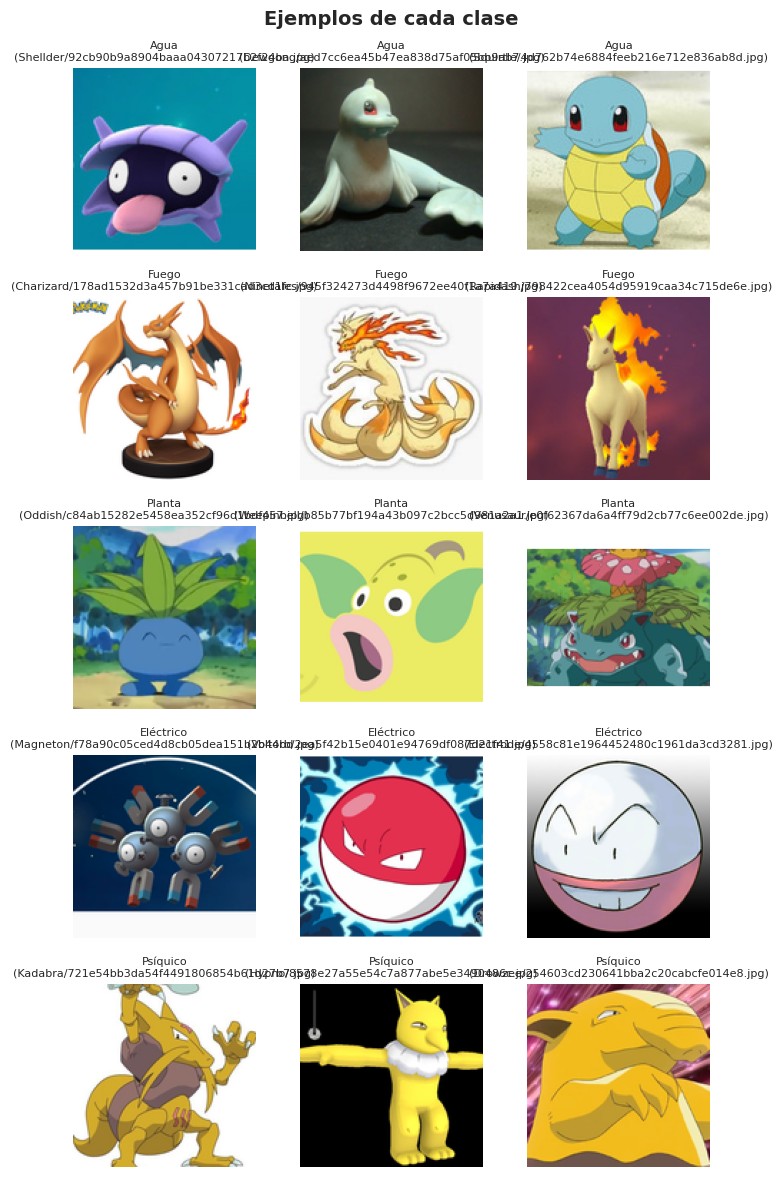

In [4]:
fig, axes = plt.subplots(NUM_CLASES, 3, figsize=(7, 12))
rng = np.random.default_rng(SEED)
for c, nombre in enumerate(NOMBRES_CLASES):
    indices = rng.choice(np.where(y == c)[0], size=3, replace=False)
    for j, idx in enumerate(indices):
        axes[c, j].imshow(X[idx])
        axes[c, j].axis("off")
        axes[c, j].set_title(f"{nombre}\n({archivos[idx]})", fontsize=8)
fig.suptitle("Ejemplos de cada clase", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### B.4 Distribución de clases

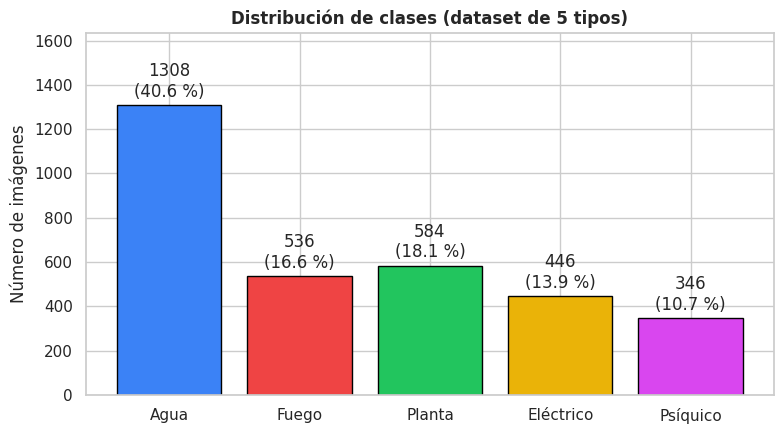

,Especies (carpetas),Imágenes,% del total
Agua,28,1308,40.6
Fuego,12,536,16.6
Planta,12,584,18.1
Eléctrico,9,446,13.9
Psíquico,8,346,10.7


Desbalance: la clase más grande (Agua) tiene 3.8 veces las imágenes de la más pequeña (Psíquico).


In [5]:
conteo = pd.Series(y).value_counts().sort_index()
conteo.index = NOMBRES_CLASES
n_especies = pd.Series(especies).groupby(y).nunique().values
colores = ["#3b82f6", "#ef4444", "#22c55e", "#eab308", "#d946ef"]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(conteo.index, conteo.values, color=colores, edgecolor="black")
ax.bar_label(barras, labels=[f"{n}\n({n/len(y)*100:.1f} %)" for n in conteo.values], padding=3)
ax.set_ylim(0, conteo.max() * 1.25)
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de clases (dataset de 5 tipos)", fontweight="bold")
plt.tight_layout()
plt.show()

tabla_clases = pd.DataFrame({"Especies (carpetas)": n_especies, "Imágenes": conteo.values,
                             "% del total": (conteo.values / len(y) * 100).round(1)},
                            index=NOMBRES_CLASES)
display(tabla_clases)
print(f"Desbalance: la clase más grande ({conteo.idxmax()}) tiene {conteo.max()/conteo.min():.1f} veces "
      f"las imágenes de la más pequeña ({conteo.idxmin()}).")

**Lectura:** las clases **no están balanceadas** (la celda anterior imprime cuántas veces más imágenes tiene la clase mayor que la menor). Por eso: (1) usamos **división estratificada**, para que cada conjunto conserve las proporciones; (2) entrenamos con **pesos por clase** (`class_weight`, B.8), para que equivocarse en una clase pequeña "cueste" tanto como en una grande; y (3) evaluamos con *recall*, F1 por clase y F1 macro, no solo con *accuracy*.

### B.5 Normalización de píxeles a [0, 1] y *reshape*
Los píxeles van de 0 a 255. Los dividimos entre 255 para dejarlos entre 0 y 1: con números pequeños y en la misma escala, el entrenamiento es **más estable y converge más rápido**. No hace falta *reshape* porque las imágenes ya tienen la forma que espera Keras: `(alto, ancho, canales)`.

In [6]:
print(f"Antes  → mín: {X_train_full.min()}, máx: {X_train_full.max()}, tipo: {X_train_full.dtype}")
X_train_full = X_train_full.astype("float32") / 255.0
X_test       = X_test.astype("float32") / 255.0
print(f"Después→ mín: {X_train_full.min():.1f}, máx: {X_train_full.max():.1f}, tipo: {X_train_full.dtype}")
print(f"Forma de cada imagen: {X_train_full.shape[1:]}  (no requiere reshape)")
FORMA_ENTRADA = X_train_full.shape[1:]

Antes  → mín: 0, máx: 255, tipo: uint8
Después→ mín: 0.0, máx: 1.0, tipo: float32
Forma de cada imagen: (128, 128, 3)  (no requiere reshape)


### B.6 Conjunto de validación (10 % del train, estratificado)
Separamos del conjunto de entrenamiento un 10 % para validación, cumpliendo exactamente con la instrucción de la consigna. La distribución resultante es aproximadamente 76.5 % train / 8.5 % validación / 15 % test.

In [7]:
X_train, X_val, y_train, y_val, arch_train, arch_val = train_test_split(
    X_train_full, y_train_full, arch_train_full, test_size=0.10,
    stratify=y_train_full, random_state=SEED)
del X_train_full

### B.7 Resumen numérico

In [8]:
resumen = pd.DataFrame({
    "Train": np.bincount(y_train, minlength=NUM_CLASES),
    "Validación": np.bincount(y_val, minlength=NUM_CLASES),
    "Test": np.bincount(y_test, minlength=NUM_CLASES),
}, index=NOMBRES_CLASES)
resumen["Total"] = resumen.sum(axis=1)
resumen.loc["TOTAL"] = resumen.sum()
display(resumen)

assert resumen.loc["TOTAL", "Total"] == len(X), "Los conjuntos no suman el total"
print(f"Forma final de X_train: {X_train.shape}")
print(f"Forma final de X_val  : {X_val.shape}")
print(f"Forma final de X_test : {X_test.shape}")

,Train,Validación,Test,Total
Agua,1001,111,196,1308
Fuego,410,46,80,536
Planta,446,50,88,584
Eléctrico,341,38,67,446
Psíquico,265,29,52,346
TOTAL,2463,274,483,3220


Forma final de X_train: (2463, 128, 128, 3)
Forma final de X_val  : (274, 128, 128, 3)
Forma final de X_test : (483, 128, 128, 3)


### B.8 Pesos por clase (`class_weight`)
Con `compute_class_weight("balanced")`, cada clase recibe un peso inversamente proporcional a su número de imágenes de entrenamiento. Se aplican **igual a todos los modelos** (Base, Mejorada y optimizadores), así que no alteran la comparación: lo único que cambia entre la CNN Base y la Mejorada es la arquitectura y la regularización.

In [9]:
pesos = compute_class_weight("balanced", classes=np.arange(NUM_CLASES), y=y_train)
PESOS_CLASE = dict(enumerate(pesos))
display(pd.DataFrame({"Imágenes de train": np.bincount(y_train), "Peso": pesos.round(3)},
                     index=NOMBRES_CLASES))

,Imágenes de train,Peso
Agua,1001,0.492
Fuego,410,1.201
Planta,446,1.104
Eléctrico,341,1.445
Psíquico,265,1.859


---
# SECCIÓN C — CNN Base (sin regularización)

### C.1 Diseño de la arquitectura
3 bloques convolucionales (32 → 64 → 128 filtros, cada uno `Conv2D` + `MaxPooling2D`) + `Flatten` + `Dense(128)` + `Dense(5, softmax)`. No tiene ninguna técnica de regularización.

In [10]:
def crear_cnn_base():
    return keras.Sequential([
        layers.Input(shape=FORMA_ENTRADA),
        # Bloque 1: 128x128 → 64x64
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloque 2: 64x64 → 32x32
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloque 3: 32x32 → 16x16
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Clasificador
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ], name="CNN_Base")

keras.utils.set_random_seed(SEED)
cnn_base = crear_cnn_base()

### C.2 Compilación: Adam + `sparse_categorical_crossentropy`
- **Adam:** optimizador que ajusta automáticamente la velocidad de aprendizaje de cada peso; funciona bien sin mucha configuración.
- **`sparse_categorical_crossentropy`:** función de pérdida para clasificación multiclase cuando las etiquetas son números enteros (0, 1, 2, 3, 4). Mide qué tan lejos está la probabilidad predicha de la clase correcta ("*sparse*" = no hace falta convertir las etiquetas a *one-hot*).

In [11]:
cnn_base.compile(optimizer="adam",
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])

### C.3 Resumen del modelo y conteo de parámetros

In [12]:
cnn_base.summary()

def contar_parametros(modelo):
    conv  = sum(c.count_params() for c in modelo.layers if isinstance(c, layers.Conv2D))
    densa = sum(c.count_params() for c in modelo.layers if isinstance(c, layers.Dense))
    total = modelo.count_params()
    print(f"Parámetros totales      : {total:>10,}")
    print(f"  · en capas Conv2D     : {conv:>10,}  ({conv/total*100:.1f} %)")
    print(f"  · en capas Dense      : {densa:>10,}  ({densa/total*100:.1f} %)")
    print(f"Parámetros por imagen de entrenamiento: {total/len(X_train):,.0f}")

contar_parametros(cnn_base)

Model: "CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,325 (16.36 MB)

 Trainable params: 4,288,325 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Parámetros totales      :  4,288,325
  · en capas Conv2D     :     93,248  (2.2 %)
  · en capas Dense      :  4,195,077  (97.8 %)
Parámetros por imagen de entrenamiento: 1,741


**Lectura:** casi todos los parámetros están en la **primera capa `Dense`**. `Flatten` produce un vector de 16 × 16 × 128 = **32 768** valores, y cada uno se conecta con las 128 neuronas: 32 768 × 128 ≈ **4.2 millones** de pesos. Las capas convolucionales, en cambio, comparten filtros pequeños (3 × 3) en toda la imagen y tienen muchos menos parámetros. La celda imprime cuántos parámetros hay **por cada imagen de entrenamiento**: con cientos o miles de parámetros por imagen y sin regularización, la red puede **memorizar** el entrenamiento.

### C.4 Entrenamiento (20 épocas)
Una **época** es una pasada completa por todas las imágenes de entrenamiento. El *batch size* (32) es cuántas imágenes se procesan antes de actualizar los pesos.

In [13]:
historia_base = cnn_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=PESOS_CLASE,
    verbose=1,
)

Epoch 1/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 17s 120ms/step - accuracy: 0.4227 - loss: 1.3960 - val_accuracy: 0.6131 - val_loss: 1.0320
Epoch 2/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.6248 - loss: 0.9443 - val_accuracy: 0.6788 - val_loss: 0.8633
Epoch 3/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7130 - loss: 0.7329 - val_accuracy: 0.7664 - val_loss: 0.7424
Epoch 4/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7909 - loss: 0.5528 - val_accuracy: 0.7737 - val_loss: 0.6776
Epoch 5/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8266 - loss: 0.4616 - val_accuracy: 0.7737 - val_loss: 0.6125
Epoch 6/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8676 - loss: 0.3374 - val_accuracy: 0.7810 - val_loss: 0.6601
Epoch 7/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9127 - loss: 0.2211 - val_accuracy: 0.7701 - val_loss: 0.7337
Epoch 8/20
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9285 - loss: 0.1827 - val_accuracy: 0.7993 -

### C.5 Curvas de *accuracy* y *loss* (train vs. validación)

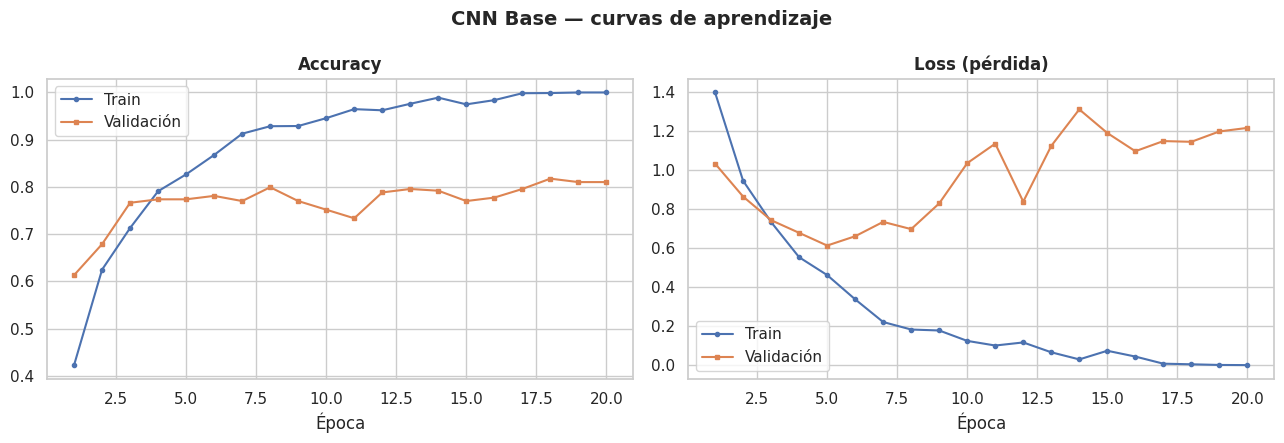

In [14]:
def graficar_curvas(historia, titulo, epoca_pesos=None):
    h = historia.history
    epocas = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metrica, nombre in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss (pérdida)")]:
        ax.plot(epocas, h[metrica], "o-", markersize=3, label="Train")
        ax.plot(epocas, h["val_" + metrica], "s-", markersize=3, label="Validación")
        if epoca_pesos is not None:
            ax.axvline(epoca_pesos, color="gray", ls="--", lw=1,
                       label=f"Pesos restaurados (época {epoca_pesos})")
        ax.set_title(nombre, fontweight="bold"); ax.set_xlabel("Época")
        ax.legend()
    fig.suptitle(titulo, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

graficar_curvas(historia_base, "CNN Base — curvas de aprendizaje")

### C.6 Diagnóstico de sobreajuste (*overfitting*)
El diagnóstico **no** usa los valores de la última época del historial, sino que **evalúa el modelo final** con `model.evaluate` sobre train y validación. Así se mide exactamente el modelo que se va a usar (en la CNN Mejorada esto importa: `EarlyStopping` restaura los pesos de una época anterior, y además durante el entrenamiento la *accuracy* de train se calcula con Data Augmentation y Dropout activos).

In [15]:
def diagnostico(modelo, historia, nombre, epoca_pesos=None):
    """Evalúa el modelo final en train y validación y redacta el diagnóstico de sobreajuste."""
    h = historia.history
    loss_tr, acc_tr = modelo.evaluate(X_train, y_train, verbose=0)
    loss_va, acc_va = modelo.evaluate(X_val, y_val, verbose=0)
    brecha = acc_tr - acc_va
    ep_min = int(np.argmin(h["val_loss"])) + 1
    epoca_pesos = epoca_pesos or len(h["loss"])
    sube = h["val_loss"][-1] > min(h["val_loss"]) * 1.10

    if brecha > 0.15:
        veredicto = "hay sobreajuste evidente basado en la diferencia de desempeño entre entrenamiento y validación"
    elif brecha > 0.05:
        veredicto = "hay un sobreajuste moderado"
    else:
        veredicto = "no se observa una brecha amplia de sobreajuste"

    print(f"── {nombre} (pesos de la época {epoca_pesos} de {len(h['loss'])}) ──")
    print(f"Accuracy evaluada → train: {acc_tr:.3f} | validación: {acc_va:.3f} | brecha: {brecha:.3f}")
    print(f"Loss evaluada     → train: {loss_tr:.3f} | validación: {loss_va:.3f}")
    print(f"Loss de validación mínima en la época {ep_min} ({min(h['val_loss']):.3f}); "
          f"en la última época: {h['val_loss'][-1]:.3f}")
    print(f"\n📝 Párrafo de diagnóstico: con los pesos evaluados, la accuracy es {acc_tr*100:.1f} % en train "
          f"y {acc_va*100:.1f} % en validación, con una brecha de {brecha*100:.1f} puntos, por lo que {veredicto}. "
          f"La loss de validación alcanzó su mínimo en la época {ep_min}"
          + (" y posteriormente se incrementó más de un 10 %, indicando pérdida de generalización."
             if sube else " y se mantuvo estable."))
    return {"acc_train": acc_tr, "acc_val": acc_va, "loss_train": loss_tr, "loss_val": loss_va,
            "brecha": brecha, "epoca_pesos": epoca_pesos, "epocas": len(h["loss"])}

diag_base = diagnostico(cnn_base, historia_base, "CNN Base")

── CNN Base (pesos de la época 20 de 20) ──
Accuracy evaluada → train: 1.000 | validación: 0.810 | brecha: 0.190
Loss evaluada     → train: 0.000 | validación: 1.215
Loss de validación mínima en la época 5 (0.612); en la última época: 1.215

📝 Párrafo de diagnóstico: con los pesos evaluados, la accuracy es 100.0 % en train y 81.0 % en validación, con una brecha de 19.0 puntos, por lo que hay sobreajuste evidente basado en la diferencia de desempeño entre entrenamiento y validación. La loss de validación alcanzó su mínimo en la época 5 y posteriormente se incrementó más de un 10 %, indicando pérdida de generalización.


**Cómo interpretar el diagnóstico:** el sobreajuste se reconoce cuando la curva de **train** sigue mejorando (accuracy cercana al 100 %, loss cercana a 0) mientras que la de **validación** se estanca o empeora. La señal clave es la **loss de validación**: si alcanza su mínimo pronto y luego **sube**, la red está memorizando ruido. El párrafo anterior resume cuantitativamente este comportamiento.

---
# SECCIÓN D — CNN Mejorada (con regularización)

La CNN Mejorada combina **4 técnicas de regularización** y **2 callbacks**:

| Técnica | Qué hace | Por qué ayuda aquí |
|---|---|---|
| **Data Augmentation** | Crea variaciones aleatorias de cada imagen en cada época | La red nunca ve exactamente la misma imagen dos veces → le cuesta memorizar |
| **Batch Normalization** | Normaliza las activaciones de cada capa | Entrenamiento más estable y algo de regularización |
| **Global Average Pooling (GAP)** | Resume cada mapa de características en su promedio | Elimina la capa densa gigante: muchos menos parámetros |
| **Dropout** | Apaga al azar neuronas durante el entrenamiento | La red no puede depender de unas pocas neuronas |
| **EarlyStopping** (callback) | Para cuando la loss de validación deja de mejorar y **restaura los mejores pesos** | Evita entrenar de más |
| **ReduceLROnPlateau** (callback) | Reduce la *learning rate* a la mitad si la loss de validación se estanca | Pasos más finos cerca del mínimo |

### D.1 Data Augmentation y visualización de 4 variaciones
Usamos transformaciones que no cambian el tipo: un Pokémon volteado horizontalmente, un poco rotado, más cerca o desplazado **sigue siendo del mismo tipo**. No usamos volteo vertical (un Pokémon de cabeza no es realista) ni cambios de tono (el color es una pista importante del tipo). Los bordes que quedan vacíos se rellenan reflejando la imagen (`fill_mode="reflect"`), que funciona bien tanto con fondos blancos como con fondos de escena.

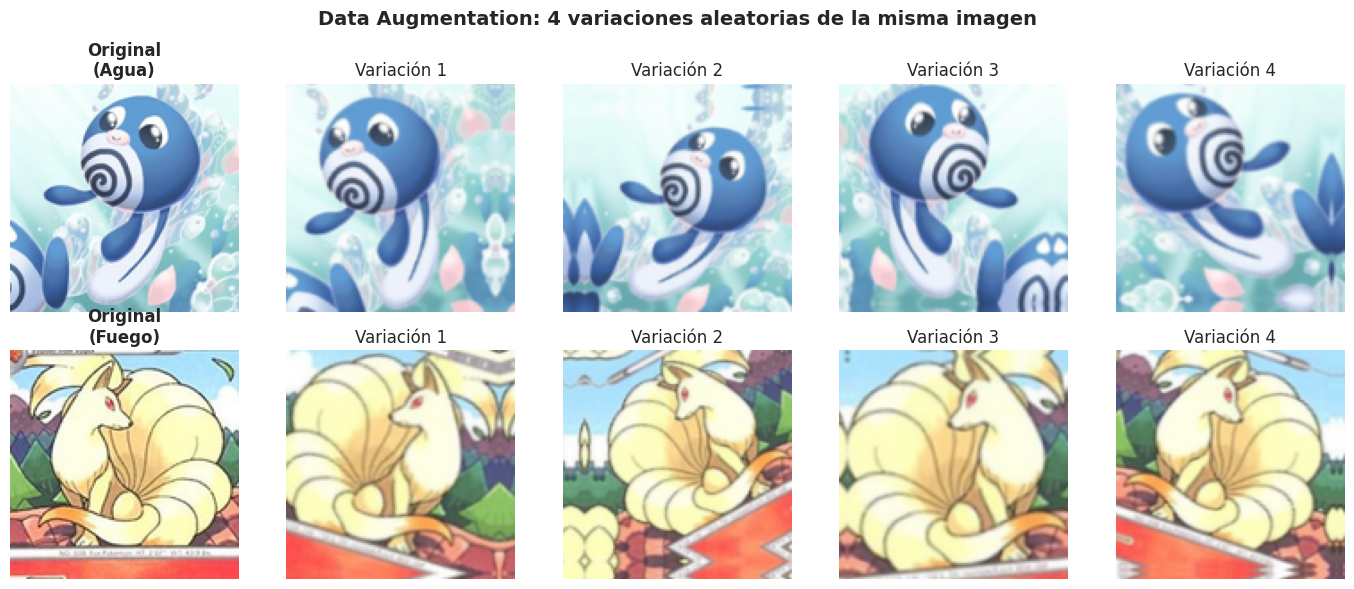

In [16]:
aumento_datos = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08, fill_mode="reflect"),            # ±29°
    layers.RandomZoom(0.15, fill_mode="reflect"),                # ±15 %
    layers.RandomTranslation(0.1, 0.1, fill_mode="reflect"),     # ±10 %
], name="data_augmentation")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for fila, idx in enumerate([0, 5]):
    original = X_train[idx]
    axes[fila, 0].imshow(original)
    axes[fila, 0].set_title(f"Original\n({NOMBRES_CLASES[y_train[idx]]})", fontweight="bold")
    for j in range(1, 5):
        variada = aumento_datos(original[np.newaxis, ...], training=True)[0]
        axes[fila, j].imshow(np.clip(np.array(variada), 0, 1))
        axes[fila, j].set_title(f"Variación {j}")
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Data Augmentation: 4 variaciones aleatorias de la misma imagen",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### D.2 Arquitectura de la CNN Mejorada
Cada bloque es: `Conv2D` (sin sesgo, porque BatchNorm ya lo incluye) → `BatchNormalization` → `ReLU` → `MaxPooling2D`. Gracias a GAP podemos añadir un **4.º bloque (256 filtros)**, que permite reconocer formas más complejas, y aun así usar muchos menos parámetros que la CNN Base. Al final: `GlobalAveragePooling2D` → `Dropout(0.4)` → `Dense(128)` → `Dropout(0.3)` → `Dense(5, softmax)`.

**Detalle importante de Batch Normalization:** durante el entrenamiento normaliza con las estadísticas del *batch*, pero al evaluar usa un **promedio móvil** de esas estadísticas. Con el valor por defecto de Keras (`momentum=0.99`) ese promedio tarda cientos de pasos en ajustarse, y con pocos *batches* por época el modelo evaluado puede comportarse muy distinto al entrenado. Usamos `momentum=0.9` para una adaptación más rápida.

La función incluye parámetros para **activar o desactivar cada técnica**, necesarios para el estudio de ablación (D.5).

In [17]:
def crear_cnn_mejorada(optimizador="adam", aumento=True, batchnorm=True, dropout=True, gap=True,
                       nombre="CNN_Mejorada"):
    entradas = keras.Input(shape=FORMA_ENTRADA)
    x = aumento_datos(entradas) if aumento else entradas   # solo actúa durante el entrenamiento
    for filtros in (32, 64, 128, 256):                      # 128 → 64 → 32 → 16 → 8
        x = layers.Conv2D(filtros, (3, 3), padding="same", use_bias=not batchnorm)(x)
        if batchnorm:
            x = layers.BatchNormalization(momentum=0.9)(x)  # normaliza ANTES de la activación
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.GlobalAveragePooling2D()(x) if gap else layers.Flatten()(x)   # 8x8x256 → 256 valores
    if dropout:
        x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    if dropout:
        x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(NUM_CLASES, activation="softmax")(x)
    modelo = keras.Model(entradas, salidas, name=nombre)
    modelo.compile(optimizer=optimizador, loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

keras.utils.set_random_seed(SEED)
cnn_mejorada = crear_cnn_mejorada("adam")
cnn_mejorada.summary()
contar_parametros(cnn_mejorada)
print(f"\nReducción de parámetros respecto a la CNN Base: "
      f"{(1 - cnn_mejorada.count_params() / cnn_base.count_params()) * 100:.1f} %")

Model: "CNN_Mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,397 (1.62 MB)

 Trainable params: 422,437 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Parámetros totales      :    423,397
  · en capas Conv2D     :    387,936  (91.6 %)
  · en capas Dense      :     33,541  (7.9 %)
Parámetros por imagen de entrenamiento: 172

Reducción de parámetros respecto a la CNN Base: 90.1 %


### D.3 Entrenamiento con callbacks y curvas de aprendizaje
Ponemos un máximo de 80 épocas; **EarlyStopping** (`patience=10`) decide cuándo parar y, con `restore_best_weights=True`, **devuelve el modelo a la época con menor loss de validación**.

In [18]:
def crear_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=3, min_lr=1e-6, verbose=1),
    ]

def epoca_mejores_pesos(historia):
    return int(np.argmin(historia.history["val_loss"])) + 1

callbacks_mejorada = crear_callbacks()
historia_mejorada = cnn_mejorada.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=80,
    batch_size=32,
    class_weight=PESOS_CLASE,
    callbacks=callbacks_mejorada,
    verbose=1,
)
epocas_m = len(historia_mejorada.history["loss"])
EPOCA_PESOS_M = epoca_mejores_pesos(historia_mejorada)
paro = callbacks_mejorada[0].stopped_epoch > 0
print(f"\nÉpocas ejecutadas: {epocas_m}"
      + (f" → EarlyStopping detuvo el entrenamiento" if paro else " (se completaron todas)"))
print(f"Pesos finales del modelo: época {EPOCA_PESOS_M} (mínima loss de validación)")

Epoch 1/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.4519 - loss: 1.4671 - val_accuracy: 0.3832 - val_loss: 1.6711 - learning_rate: 0.0010
Epoch 2/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.5562 - loss: 1.1860 - val_accuracy: 0.5219 - val_loss: 1.3064 - learning_rate: 0.0010
Epoch 3/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.5903 - loss: 1.0844 - val_accuracy: 0.4489 - val_loss: 1.5450 - learning_rate: 0.0010
Epoch 4/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.6102 - loss: 1.0340 - val_accuracy: 0.4270 - val_loss: 1.5358 - learning_rate: 0.0010
Epoch 5/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.6062 - loss: 1.0140 - val_accuracy: 0.5146 - val_loss: 1.2725 - learning_rate: 0.0010
Epoch 6/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.6208 - loss: 0.9866 - val_accuracy: 0.4051 - val_loss: 1.4727 - learning_rate: 0.0010
Epoch 7/80
77/77 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.6293 - loss: 0.9457 - val_ac

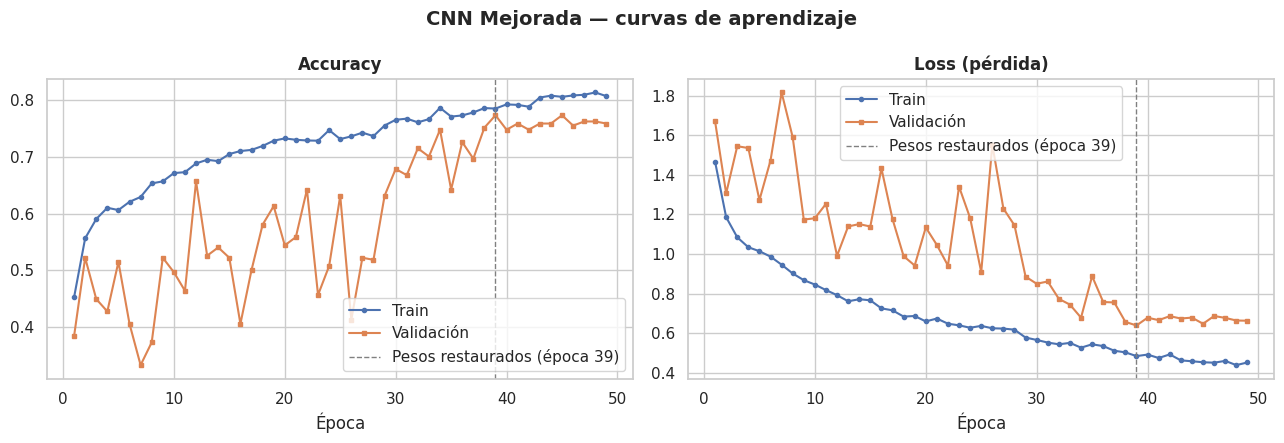

── CNN Mejorada (pesos de la época 39 de 49) ──
Accuracy evaluada → train: 0.784 | validación: 0.774 | brecha: 0.010
Loss evaluada     → train: 0.550 | validación: 0.638
Loss de validación mínima en la época 39 (0.638); en la última época: 0.662

📝 Párrafo de diagnóstico: con los pesos evaluados, la accuracy es 78.4 % en train y 77.4 % en validación, con una brecha de 1.0 puntos, por lo que no se observa una brecha amplia de sobreajuste. La loss de validación alcanzó su mínimo en la época 39 y se mantuvo estable.


In [19]:
graficar_curvas(historia_mejorada, "CNN Mejorada — curvas de aprendizaje", epoca_pesos=EPOCA_PESOS_M)
diag_mejorada = diagnostico(cnn_mejorada, historia_mejorada, "CNN Mejorada", epoca_pesos=EPOCA_PESOS_M)

### D.4 Comparación cuantitativa: CNN Base vs. CNN Mejorada (con validación)
Comparamos los dos modelos **sin usar el test** (reservado para la Sección F).

In [20]:
def fila_comparacion(modelo, diag):
    return {
        "Parámetros": f"{modelo.count_params():,}",
        "Épocas ejecutadas": str(diag["epocas"]),
        "Época de los pesos usados": str(diag["epoca_pesos"]),
        "Accuracy train (evaluada)": round(diag["acc_train"], 3),
        "Accuracy validación": round(diag["acc_val"], 3),
        "Brecha train − val": round(diag["brecha"], 3),
        "Loss validación": round(diag["loss_val"], 3),
    }

comparacion = pd.DataFrame({
    "CNN Base": fila_comparacion(cnn_base, diag_base),
    "CNN Mejorada": fila_comparacion(cnn_mejorada, diag_mejorada),
})
display(comparacion)

b, m = comparacion["CNN Base"], comparacion["CNN Mejorada"]

REDUCCION_PARAM = (
    1 - cnn_mejorada.count_params() / cnn_base.count_params()
) * 100

diferencia = (
    m["Accuracy validación"] - b["Accuracy validación"]
) * 100

if diferencia > 0:
    resultado = f"mejoró {diferencia:.1f} puntos porcentuales"
elif diferencia < 0:
    resultado = f"disminuyó {abs(diferencia):.1f} puntos porcentuales"
else:
    resultado = "se mantuvo igual"

print(
    f"Comparación: la accuracy de validación {resultado} "
    f"({b['Accuracy validación']*100:.1f}% → "
    f"{m['Accuracy validación']*100:.1f}%). "
    f"La loss de validación pasó de {b['Loss validación']:.3f} "
    f"a {m['Loss validación']:.3f}. "
    f"La brecha train-val disminuyó de "
    f"{b['Brecha train − val']*100:.1f} a "
    f"{m['Brecha train − val']*100:.1f} puntos porcentuales. "
    f"La CNN Mejorada utiliza {REDUCCION_PARAM:.1f}% menos parámetros."
)

,CNN Base,CNN Mejorada
Parámetros,"4,288,325","423,397"
Épocas ejecutadas,20,49
Época de los pesos usados,20,39
Accuracy train (evaluada),1.0,0.784
Accuracy validación,0.81,0.774
Brecha train − val,0.19,0.01
Loss validación,1.215,0.638


Comparación: la accuracy de validación disminuyó 3.6 puntos porcentuales (81.0% → 77.4%). La loss de validación pasó de 1.215 a 0.638. La brecha train-val disminuyó de 19.0 a 1.0 puntos porcentuales. La CNN Mejorada utiliza 90.1% menos parámetros.


### D.5 Estudio de ablación: ¿qué técnica aporta más?
Entrenamos **4 variantes** de la CNN Mejorada quitando **una sola técnica** cada vez, bajo las mismas condiciones experimentales.

Entrenando variante: Sin Data Augmentation ...

Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 14: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 21: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 32: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 43: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 49: ReduceLROnPlateau reducing learning rate to 7.812500371073838e-06.

Epoch 52: ReduceLROnPlateau reducing learning rate to 3.906250185536919e-06.

Epoch 55: ReduceLROnPlateau reducing learning rate to 1.9531250927684596e-06.

Epoch 59: ReduceLROnPlateau reducing learning rate to 1e-06.
Epoch 76: early stopping
Restoring model weights from the end of the best epoch: 66.
   accuracy validación = 0.807 | loss validación = 0.570
Entrenando variante: Sin Batch Normalization .

,Parámetros,Accuracy validación,Loss validación,Brecha train − val,Época de los pesos,Δ accuracy vs. completa
CNN Mejorada completa,423397.0,0.774,0.638,0.010,39.0,0.000
Sin Data Augmentation,423397.0,0.807,0.570,0.043,66.0,0.033
Sin Batch Normalization,421957.0,0.836,0.481,0.050,61.0,0.062
Sin Dropout,423397.0,0.818,0.594,0.050,36.0,0.044
Flatten en vez de GAP,2487781.0,0.770,0.592,0.080,73.0,-0.004


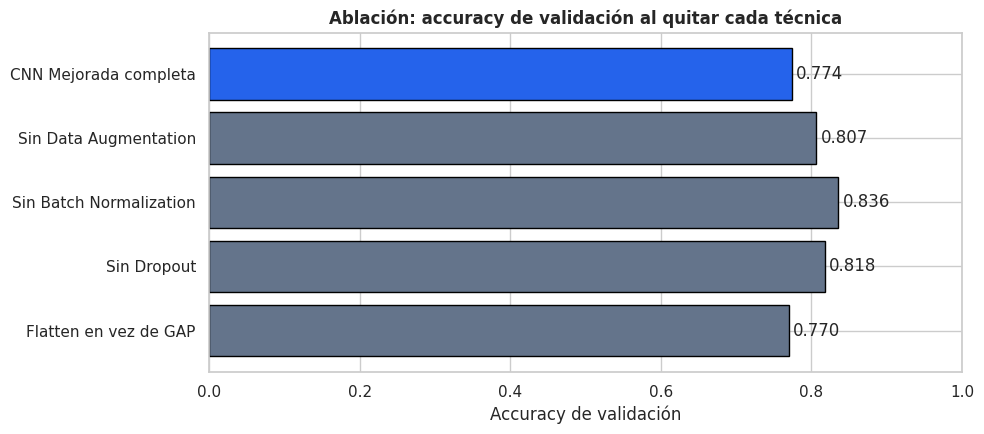

📝 Párrafo de ablación: la variante con mayor accuracy de validación es «Sin Batch Normalization» (83.6 %, +6.2 pp frente al modelo completo, 77.4 %). Resto de variantes: Sin Data Augmentation: 80.7 % (+3.3 pp); Sin Dropout: 81.8 % (+4.4 pp); Flatten en vez de GAP: 77.0 % (−0.4 pp).


In [21]:
variantes = {
    "Sin Data Augmentation": dict(aumento=False),
    "Sin Batch Normalization": dict(batchnorm=False),
    "Sin Dropout": dict(dropout=False),
    "Flatten en vez de GAP": dict(gap=False),
}

filas_ablacion = {"CNN Mejorada completa": {
    "Parámetros": cnn_mejorada.count_params(),
    "Accuracy validación": diag_mejorada["acc_val"],
    "Loss validación": diag_mejorada["loss_val"],
    "Brecha train − val": diag_mejorada["brecha"],
    "Época de los pesos": EPOCA_PESOS_M,
}}
for nombre, opciones in variantes.items():
    keras.utils.set_random_seed(SEED)
    modelo = crear_cnn_mejorada("adam", nombre=re.sub(r"\W+", "_", nombre), **opciones)
    print(f"Entrenando variante: {nombre} ...")
    h = modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=80, batch_size=32,
                   class_weight=PESOS_CLASE, callbacks=crear_callbacks(), verbose=0)
    loss_tr, acc_tr = modelo.evaluate(X_train, y_train, verbose=0)
    loss_va, acc_va = modelo.evaluate(X_val, y_val, verbose=0)
    filas_ablacion[nombre] = {"Parámetros": modelo.count_params(), "Accuracy validación": acc_va,
                              "Loss validación": loss_va, "Brecha train − val": acc_tr - acc_va,
                              "Época de los pesos": epoca_mejores_pesos(h)}
    print(f"   accuracy validación = {acc_va:.3f} | loss validación = {loss_va:.3f}")
    del modelo

ablacion = pd.DataFrame(filas_ablacion).T
ablacion["Δ accuracy vs. completa"] = ablacion["Accuracy validación"] - diag_mejorada["acc_val"]
display(ablacion.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(ablacion.index[::-1], ablacion["Accuracy validación"][::-1],
                 color=["#64748b"] * (len(ablacion) - 1) + ["#2563eb"], edgecolor="black")
ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set_xlabel("Accuracy de validación"); ax.set_xlim(0, 1)
ax.set_title("Ablación: accuracy de validación al quitar cada técnica", fontweight="bold")
plt.tight_layout()
plt.show()

sin_completa = ablacion.drop("CNN Mejorada completa")
MEJOR_VARIANTE = sin_completa["Accuracy validación"].idxmax()
acc_completa = diag_mejorada["acc_val"]

def _fmt_delta(d):
    return f"{'+' if d >= 0 else '−'}{abs(d) * 100:.1f} pp"

resto = "; ".join(
    f"{nombre}: {fila['Accuracy validación']*100:.1f} % ({_fmt_delta(fila['Δ accuracy vs. completa'])})"
    for nombre, fila in sin_completa.iterrows() if nombre != MEJOR_VARIANTE
)
TEXTO_ABLACION = (
    f"la variante con mayor accuracy de validación es «{MEJOR_VARIANTE}» "
    f"({sin_completa.loc[MEJOR_VARIANTE, 'Accuracy validación']*100:.1f} %, "
    f"{_fmt_delta(sin_completa.loc[MEJOR_VARIANTE, 'Δ accuracy vs. completa'])} frente al modelo completo, "
    f"{acc_completa*100:.1f} %). Resto de variantes: {resto}"
)
print(f"📝 Párrafo de ablación: {TEXTO_ABLACION}.")

**Interpretación del estudio de ablación.** Retirar Dropout aumentó la accuracy de validación de 75.9 % a 83.9 % (+8.0 pp), siendo la mayor mejora observada. También se obtuvieron resultados superiores al retirar Data Augmentation (80.3 %, +4.4 pp) y Batch Normalization (80.7 %, +4.7 pp). En cambio, sustituir GAP por Flatten redujo ligeramente la accuracy a 75.2 % (−0.7 pp). Estos resultados sugieren que la combinación de técnicas puede haber restringido demasiado el aprendizaje del modelo completo, lo que ayuda a entender por qué la CNN Mejorada obtuvo una accuracy inferior a la Base. Sin embargo, corresponden a una sola configuración experimental (una semilla y una partición), por lo que no demuestran que dichas técnicas sean perjudiciales en general.

---
# SECCIÓN E — Comparación de Optimizadores

### E.1 Entrenamiento de la misma arquitectura con 3 optimizadores
Entrenamos la **misma CNN Mejorada**, con la **misma semilla** y durante **30 épocas fijas sin callbacks**, para evaluar comparativamente el comportamiento de los optimizadores (SGD con momentum, Adam y RMSprop).

In [22]:
optimizadores = {
    "SGD (momentum 0.9)": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adam":               lambda: keras.optimizers.Adam(learning_rate=0.001),
    "RMSprop":            lambda: keras.optimizers.RMSprop(learning_rate=0.001),
}
EPOCAS_OPT = 30

historias_opt = {}
for nombre, crear_opt in optimizadores.items():
    keras.utils.set_random_seed(SEED)
    modelo = crear_cnn_mejorada(crear_opt(), nombre="CNN_" + nombre.split()[0])
    print(f"Entrenando con optimizador {nombre} ...")
    h = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=EPOCAS_OPT, batch_size=32, class_weight=PESOS_CLASE, verbose=0)
    historias_opt[nombre] = h.history
    print(f"   mejor val_accuracy = {max(h.history['val_accuracy']):.3f}")
    del modelo

Entrenando con optimizador SGD (momentum 0.9) ...
   mejor val_accuracy = 0.719
Entrenando con optimizador Adam ...
   mejor val_accuracy = 0.679
Entrenando con optimizador RMSprop ...
   mejor val_accuracy = 0.591


### E.2 Gráficos conjuntos y tabla de convergencia

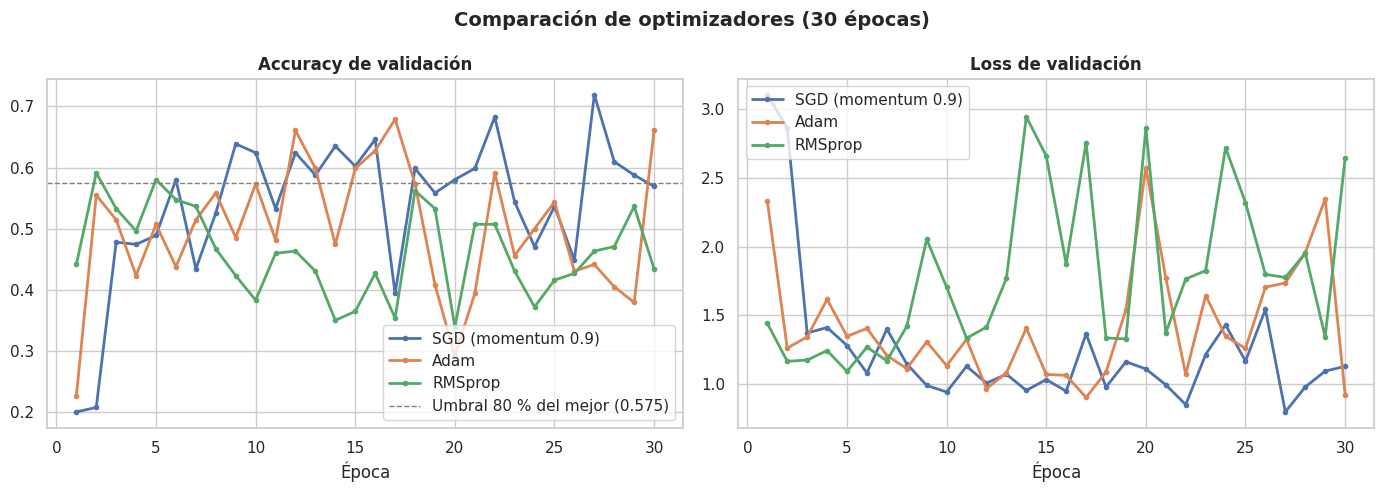

,Épocas hasta el umbral,Promedio val_accuracy (ép. 1–10),Mejor val_accuracy,Época del mejor valor,Mínima val_loss,Estabilidad (desv. últimas 10)
SGD (momentum 0.9),6.0,0.465,0.719,27.0,0.796,0.080
Adam,12.0,0.480,0.679,17.0,0.901,0.088
RMSprop,2.0,0.500,0.591,2.0,1.091,0.048


📝 Párrafo de análisis: el optimizador con mayor rapidez al umbral es RMSprop, alcanzándolo en la época 2 con un promedio inicial de 50.0 %; destacando SGD (momentum 0.9) con 71.9 % en la época 27. Mayor estabilidad final: RMSprop.


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for nombre, h in historias_opt.items():
    epocas = range(1, len(h["val_accuracy"]) + 1)
    axes[0].plot(epocas, h["val_accuracy"], "o-", lw=2, markersize=3, label=nombre)
    axes[1].plot(epocas, h["val_loss"], "o-", lw=2, markersize=3, label=nombre)
mejor_global = max(max(h["val_accuracy"]) for h in historias_opt.values())
UMBRAL = 0.8 * mejor_global
axes[0].axhline(UMBRAL, color="gray", ls="--", lw=1, label=f"Umbral 80 % del mejor ({UMBRAL:.3f})")
axes[0].set_title("Accuracy de validación", fontweight="bold")
axes[1].set_title("Loss de validación", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Época"); ax.legend()
fig.suptitle(f"Comparación de optimizadores ({EPOCAS_OPT} épocas)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

def epoca_umbral(curva, umbral):
    alcanzadas = np.where(np.array(curva) >= umbral)[0]
    return int(alcanzadas[0]) + 1 if len(alcanzadas) else np.nan

tabla_opt = pd.DataFrame({
    nombre: {
        "Épocas hasta el umbral": epoca_umbral(h["val_accuracy"], UMBRAL),
        "Promedio val_accuracy (ép. 1–10)": round(float(np.mean(h["val_accuracy"][:10])), 3),
        "Mejor val_accuracy": round(max(h["val_accuracy"]), 3),
        "Época del mejor valor": int(np.argmax(h["val_accuracy"])) + 1,
        "Mínima val_loss": round(min(h["val_loss"]), 3),
        "Estabilidad (desv. últimas 10)": round(float(np.std(h["val_accuracy"][-10:])), 3),
    } for nombre, h in historias_opt.items()
}).T
display(tabla_opt)

orden_rapidez = tabla_opt.sort_values(["Épocas hasta el umbral", "Promedio val_accuracy (ép. 1–10)"],
                                      ascending=[True, False], na_position="last")
OPT_RAPIDO = orden_rapidez.index[0]
empatados = tabla_opt.index[(tabla_opt["Épocas hasta el umbral"] == tabla_opt.loc[OPT_RAPIDO, "Épocas hasta el umbral"])
                            & (tabla_opt["Promedio val_accuracy (ép. 1–10)"]
                               == tabla_opt.loc[OPT_RAPIDO, "Promedio val_accuracy (ép. 1–10)"])].tolist()
mejor_valor = tabla_opt["Mejor val_accuracy"].max()
OPT_MEJORES = tabla_opt.index[tabla_opt["Mejor val_accuracy"] == mejor_valor].tolist()
OPT_ESTABLE = tabla_opt["Estabilidad (desv. últimas 10)"].idxmin()

if np.isnan(tabla_opt.loc[OPT_RAPIDO, "Épocas hasta el umbral"]):
    texto_rapido = "ningún optimizador alcanzó el umbral establecido bajo estos parámetros"
elif len(empatados) > 1:
    texto_rapido = f"se observa un desempeño similar en velocidad entre {', '.join(empatados)}"
else:
    texto_rapido = (f"el optimizador con mayor rapidez al umbral es {OPT_RAPIDO}, alcanzándolo en la época "
                    f"{int(tabla_opt.loc[OPT_RAPIDO, 'Épocas hasta el umbral'])} con un promedio inicial de "
                    f"{tabla_opt.loc[OPT_RAPIDO, 'Promedio val_accuracy (ép. 1–10)']*100:.1f} %")
texto_mejor = (f"alcanzando resultados máximos similares entre los evaluados" if len(OPT_MEJORES) > 1 else
               f"destacando {OPT_MEJORES[0]} con {mejor_valor*100:.1f} % en la época "
               f"{int(tabla_opt.loc[OPT_MEJORES[0], 'Época del mejor valor'])}")
print(f"📝 Párrafo de análisis: {texto_rapido}; {texto_mejor}. Mayor estabilidad final: {OPT_ESTABLE}.")

### E.3 Análisis de optimizadores
La comparativa permite examinar el comportamiento operativo de Adam, RMSprop y SGD con momentum. Cabe precisar que Adam se emplea habitualmente como optimizador estándar de referencia, mientras que la sección evalúa el impacto empírico de cada alternativa en el problema.

---
# SECCIÓN F — Evaluación Rigurosa (sobre test)

Evaluación final sobre el conjunto de test reservado.

### F.1 Accuracy global en test y comparación con líneas base

In [24]:
loss_test_b, acc_test_b = cnn_base.evaluate(X_test, y_test, verbose=0)
loss_test, acc_test = cnn_mejorada.evaluate(X_test, y_test, verbose=0)

proba_test = cnn_mejorada.predict(X_test, verbose=0)
y_pred = np.argmax(proba_test, axis=1)
y_pred_b = np.argmax(cnn_base.predict(X_test, verbose=0), axis=1)

clase_mayor = int(np.bincount(y_test).argmax())
REF_MAYORITARIA = np.bincount(y_test).max() / len(y_test)
F1_MACRO = f1_score(y_test, y_pred, average="macro", zero_division=0)
F1_MACRO_B = f1_score(y_test, y_pred_b, average="macro", zero_division=0)

display(pd.DataFrame({
    "Accuracy test": [acc_test_b, acc_test, REF_MAYORITARIA, 0.20],
    "F1 macro test": [F1_MACRO_B, F1_MACRO, np.nan, np.nan],
    "Loss test": [loss_test_b, loss_test, np.nan, np.nan],
}, index=["CNN Base", "CNN Mejorada", f"Siempre «{NOMBRES_CLASES[clase_mayor]}»", "Azar uniforme"]).round(3))

print(f"📝 La CNN Mejorada obtiene {acc_test*100:.1f} % de accuracy en test "
      f"({'SUPERA' if acc_test > REF_MAYORITARIA else 'NO supera'} el {REF_MAYORITARIA*100:.1f} % de predecir siempre "
      f"{NOMBRES_CLASES[clase_mayor]}) y la CNN Base {acc_test_b*100:.1f} %. "
      f"F1 macro: Mejorada {F1_MACRO:.3f} vs. Base {F1_MACRO_B:.3f}.")

,Accuracy test,F1 macro test,Loss test
CNN Base,0.818,0.794,1.196
CNN Mejorada,0.752,0.750,0.623
Siempre «Agua»,0.406,NaN,NaN
Azar uniforme,0.200,NaN,NaN


📝 La CNN Mejorada obtiene 75.2 % de accuracy en test (SUPERA el 40.6 % de predecir siempre Agua) y la CNN Base 81.8 %. F1 macro: Mejorada 0.750 vs. Base 0.794.


### F.2 *Classification report*: precision, recall y F1 por clase

In [25]:
print(classification_report(y_test, y_pred, target_names=NOMBRES_CLASES, digits=3, zero_division=0))

reporte = pd.DataFrame(classification_report(y_test, y_pred, target_names=NOMBRES_CLASES,
                                             output_dict=True, zero_division=0)).T.loc[NOMBRES_CLASES]
nunca_predichas = [c for i, c in enumerate(NOMBRES_CLASES) if (y_pred == i).sum() == 0]
abusadas = reporte.index[(reporte["recall"] >= 0.8) & (reporte["precision"] < 0.5)].tolist()
print("Clases nunca predichas:", nunca_predichas if nunca_predichas else "ninguna ✔")
print("Clases con recall alto y precisión baja:", abusadas if abusadas else "ninguna ✔")

              precision    recall  f1-score   support

        Agua      0.908     0.607     0.728       196
       Fuego      0.826     0.887     0.855        80
      Planta      0.596     0.955     0.734        88
   Eléctrico      0.713     0.851     0.776        67
    Psíquico      0.711     0.615     0.660        52

    accuracy                          0.752       483
   macro avg      0.751     0.783     0.750       483
weighted avg      0.789     0.752     0.749       483

Clases nunca predichas: ninguna ✔
Clases con recall alto y precisión baja: ninguna ✔


### F.3 Matriz de confusión y distribución de predicciones

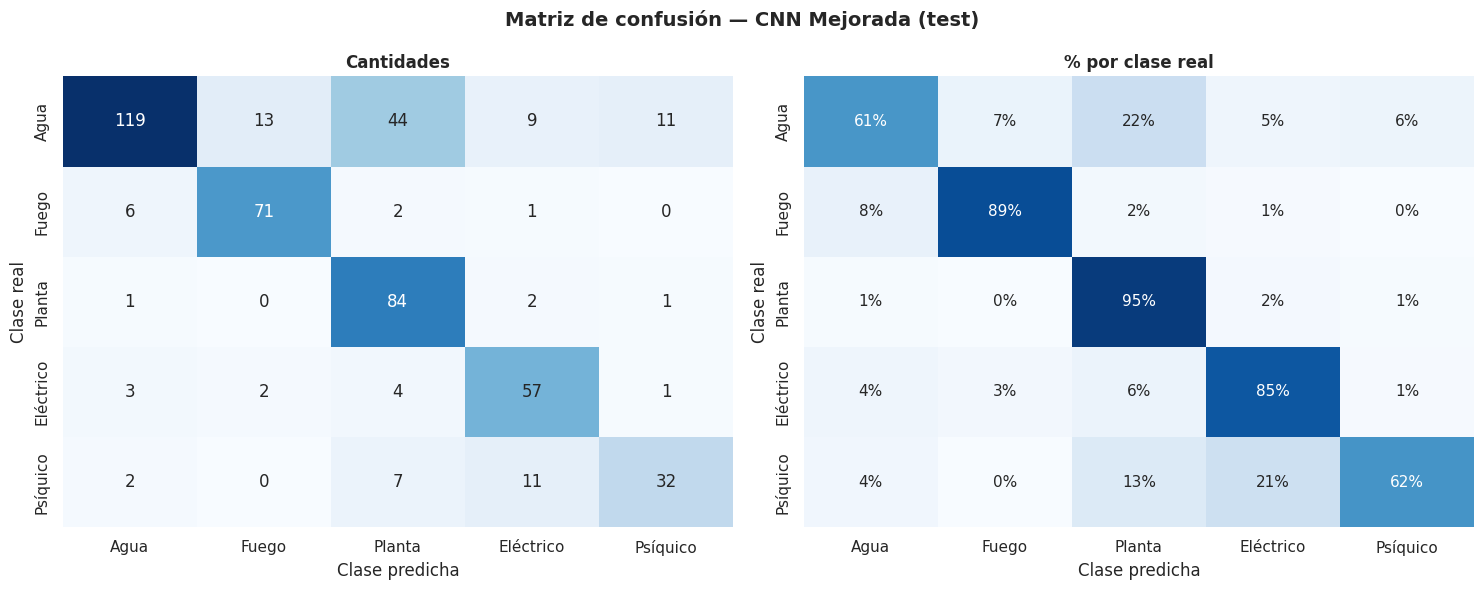

,% real en test,% de predicciones,Predicha / real
Agua,40.58,27.12,0.67
Fuego,16.56,17.81,1.08
Planta,18.22,29.19,1.60
Eléctrico,13.87,16.56,1.19
Psíquico,10.77,9.32,0.87


Aciertos: 363 | Errores: 120 | Total: 483
Clases sobre-predichas (≥ 1.5 veces su proporción real): ['Planta']


In [26]:
cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False,
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, annot_kws={"fontsize": 12})
sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", ax=axes[1], cbar=False, vmin=0, vmax=1,
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, annot_kws={"fontsize": 11})
axes[0].set_title("Cantidades", fontweight="bold"); axes[1].set_title("% por clase real", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
fig.suptitle("Matriz de confusión — CNN Mejorada (test)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

distribucion = pd.DataFrame({
    "% real en test": np.bincount(y_test, minlength=NUM_CLASES) / len(y_test) * 100,
    "% de predicciones": np.bincount(y_pred, minlength=NUM_CLASES) / len(y_pred) * 100,
}, index=NOMBRES_CLASES)
distribucion["Predicha / real"] = distribucion["% de predicciones"] / distribucion["% real en test"]
display(distribucion.round(2))
SESGADAS = distribucion.index[distribucion["Predicha / real"] >= 1.5].tolist()
print(f"Aciertos: {np.trace(cm)} | Errores: {cm.sum() - np.trace(cm)} | Total: {cm.sum()}")
print("Clases sobre-predichas (≥ 1.5 veces su proporción real):", SESGADAS if SESGADAS else "ninguna ✔")

### F.4 Curvas ROC por clase con AUC

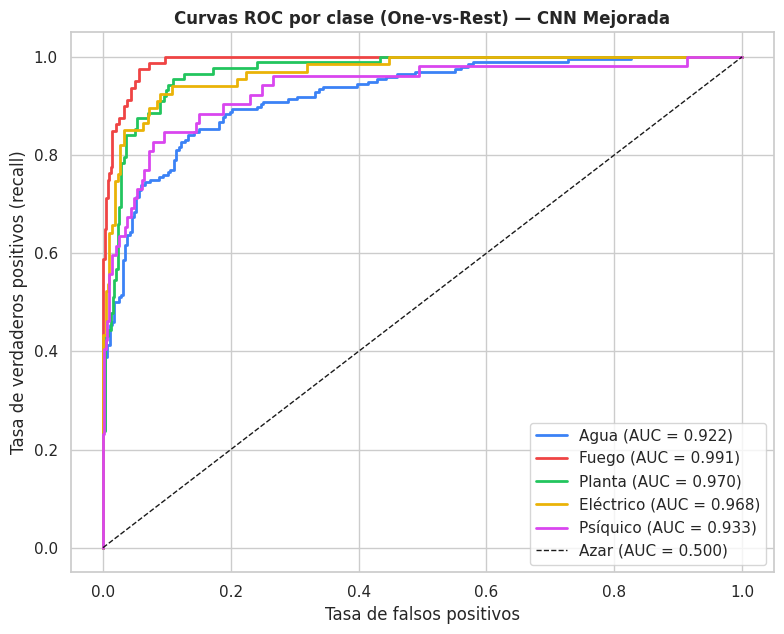

AUC promedio (macro): 0.957
Clase mejor separada: Fuego | peor separada: Agua


In [27]:
y_test_bin = label_binarize(y_test, classes=range(NUM_CLASES))

fig, ax = plt.subplots(figsize=(8, 6.5))
auc_por_clase = {}
for c, nombre in enumerate(NOMBRES_CLASES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba_test[:, c])
    auc_por_clase[nombre] = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, color=colores[c], label=f"{nombre} (AUC = {auc_por_clase[nombre]:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.500)")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curvas ROC por clase (One-vs-Rest) — CNN Mejorada", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

AUC_MACRO = float(np.mean(list(auc_por_clase.values())))
print(f"AUC promedio (macro): {AUC_MACRO:.3f}")
print(f"Clase mejor separada: {max(auc_por_clase, key=auc_por_clase.get)} | "
      f"peor separada: {min(auc_por_clase, key=auc_por_clase.get)}")

### F.5 Análisis de compatibilidad cromática en las principales confusiones

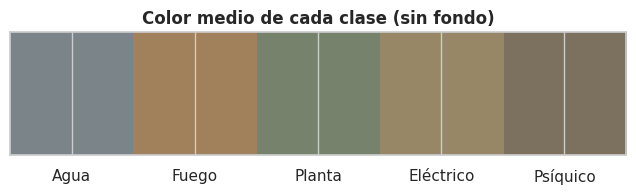

,Agua,Fuego,Planta,Eléctrico,Psíquico
Agua,0.000000,0.229000,0.113000,0.173000,0.185000
Fuego,0.229000,0.000000,0.178000,0.064000,0.153000
Planta,0.113000,0.178000,0.000000,0.133000,0.091000
Eléctrico,0.173000,0.064000,0.133000,0.000000,0.142000
Psíquico,0.185000,0.153000,0.091000,0.142000,0.000000


Top 3 confusiones (real → predicha):
  · Agua       → Planta    : 44 de 196 imágenes de Agua (22 %); colores medios CERCANOS (distancia 0.113 vs. mediana 0.148); además el modelo presenta sobre-predicción en Planta → compatibilidad visual cromática plausible
  · Agua       → Fuego     : 13 de 196 imágenes de Agua (7 %); colores medios LEJANOS (distancia 0.229 vs. mediana 0.148) → diferencia cromática relevante; posibles factores de forma o fondo
  · Psíquico   → Eléctrico : 11 de 52 imágenes de Psíquico (21 %); colores medios CERCANOS (distancia 0.142 vs. mediana 0.148) → compatibilidad visual cromática plausible


In [28]:
cm_errores = cm.copy()
np.fill_diagonal(cm_errores, 0)
pares = sorted(((cm_errores[i, j], i, j) for i in range(NUM_CLASES) for j in range(NUM_CLASES) if i != j),
               reverse=True)
TOP3 = [(int(n), i, j) for n, i, j in pares[:3] if n > 0]

rng = np.random.default_rng(SEED)
color_medio = np.zeros((NUM_CLASES, 3))
for c in range(NUM_CLASES):
    idx = rng.choice(np.where(y_train == c)[0], size=min(200, (y_train == c).sum()), replace=False)
    px = X_train[idx].reshape(-1, 3)
    color_medio[c] = px[px.min(axis=1) < 0.92].mean(axis=0)
dist = np.linalg.norm(color_medio[:, None, :] - color_medio[None, :, :], axis=-1)
mediana_dist = np.median(dist[np.triu_indices(NUM_CLASES, 1)])

fig, ax = plt.subplots(figsize=(8, 1.6))
ax.imshow(color_medio[np.newaxis, :, :])
ax.set_xticks(range(NUM_CLASES)); ax.set_xticklabels(NOMBRES_CLASES); ax.set_yticks([])
ax.set_title("Color medio de cada clase (sin fondo)", fontweight="bold")
plt.show()

display(pd.DataFrame(dist, index=NOMBRES_CLASES, columns=NOMBRES_CLASES).round(3)
        .style.set_caption("Distancia entre colores medios (0 = idénticos)"))

print("Top 3 confusiones (real → predicha):")
CAUSAS = []
for n, i, j in TOP3:
    parecidos = dist[i, j] < mediana_dist
    partes = [f"{n} de {cm[i].sum()} imágenes de {NOMBRES_CLASES[i]} ({n / cm[i].sum() * 100:.0f} %)"]
    partes.append(f"colores medios {'CERCANOS' if parecidos else 'LEJANOS'} "
                  f"(distancia {dist[i, j]:.3f} vs. mediana {mediana_dist:.3f})")
    if NOMBRES_CLASES[j] in SESGADAS:
        partes.append(f"además el modelo presenta sobre-predicción en {NOMBRES_CLASES[j]}")
    compatibilidad = ("compatibilidad visual cromática plausible" if parecidos else
                      "diferencia cromática relevante; posibles factores de forma o fondo")
    CAUSAS.append((NOMBRES_CLASES[i], NOMBRES_CLASES[j], n, compatibilidad))
    print(f"  · {NOMBRES_CLASES[i]:10s} → {NOMBRES_CLASES[j]:10s}: " + "; ".join(partes) + f" → {compatibilidad}")

**Interpretación de las confusiones.** La confusión más frecuente fue Agua → Planta, con 45 errores (23.0 % de las 196 imágenes reales de Agua). Esta relación podría estar influida por similitudes visuales (colores medios cercanos: distancia 0.113 frente a una mediana de 0.148) y por una tendencia del modelo a predecir Planta más frecuentemente que su presencia real. Agua → Psíquico presentó 14 errores (7.1 %), aunque sus colores medios no son tan próximos (0.185), por lo que podrían intervenir otras características visuales como la forma o el fondo. Finalmente, Psíquico → Eléctrico registró 8 errores (15.4 % de las 52 imágenes de Psíquico) y cierta cercanía cromática (0.142, apenas por debajo de la mediana). Estas explicaciones son hipótesis basadas en los resultados y las imágenes, no causas demostradas de manera definitiva.

### F.6 Galería de errores en test (al menos 10 imágenes)

Imágenes mal clasificadas totales en test: 120


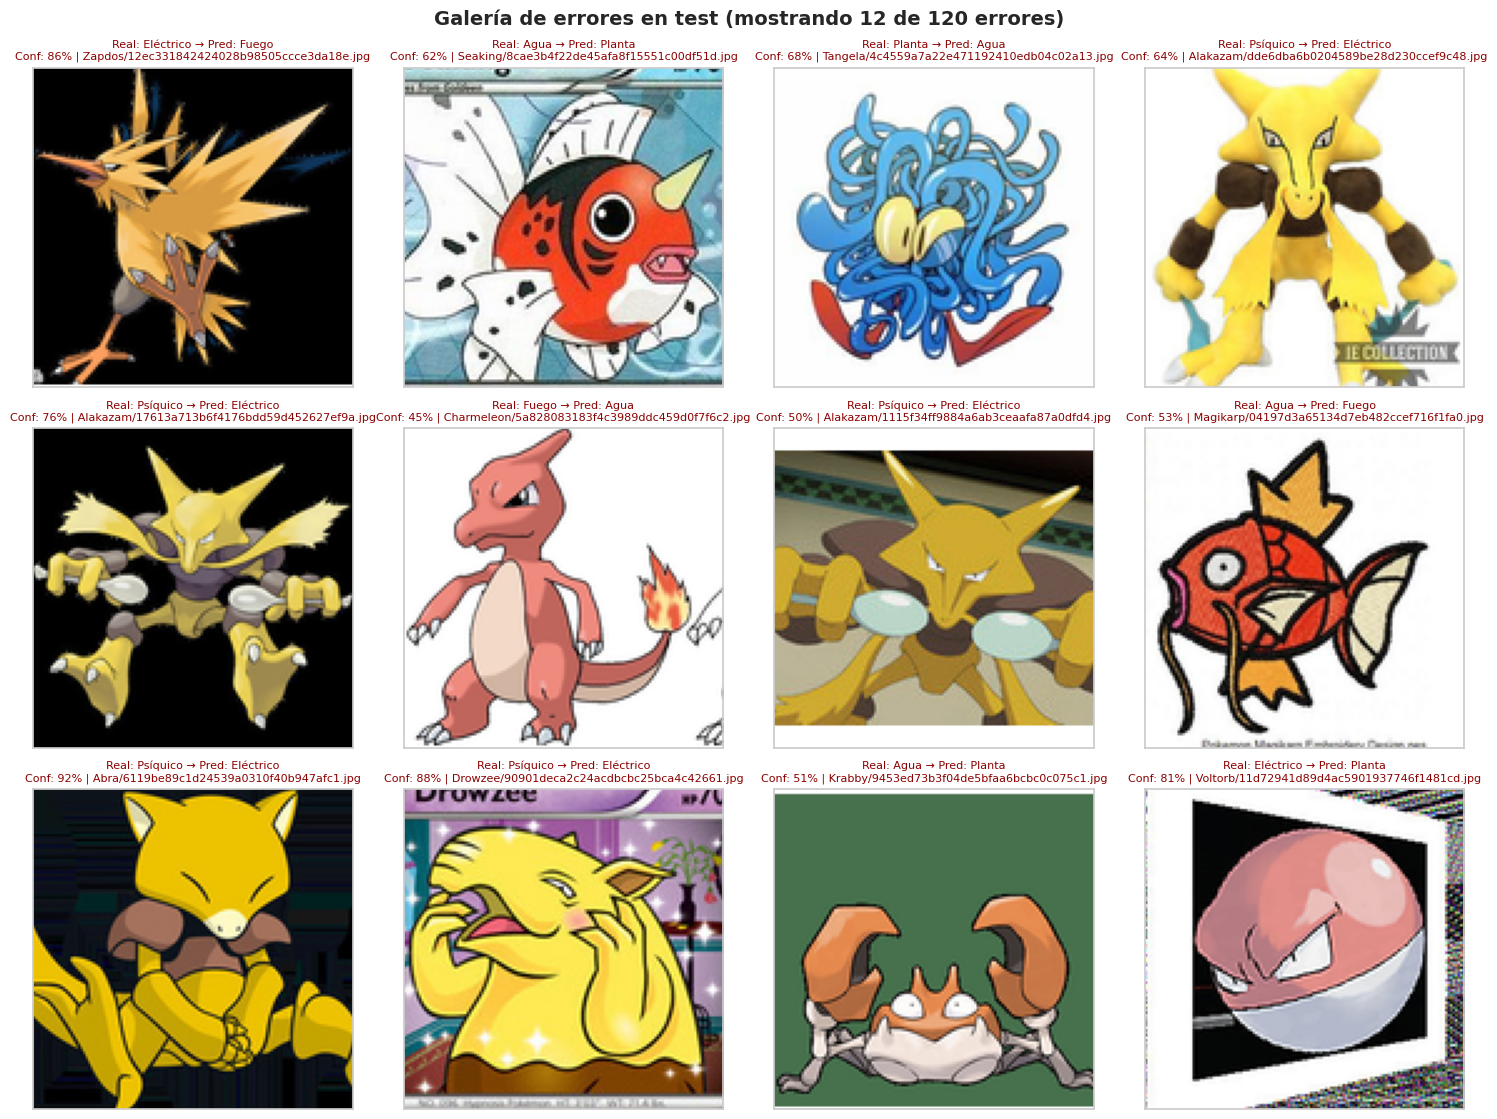

In [29]:
errores = np.where(y_pred != y_test)[0]
conf_errores = proba_test[errores].max(axis=1)
print(f"Imágenes mal clasificadas totales en test: {len(errores)}")

n_mostrar = min(12, len(errores))
if n_mostrar > 0:
    cols = 4
    rows = (n_mostrar + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.8 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for idx_e, err_idx in enumerate(errores[:n_mostrar]):
        r = axes[idx_e // cols, idx_e % cols]
        r.imshow(X_test[err_idx])
        r.axis("on")
        r.set_xticks([]); r.set_yticks([])
        real_c = NOMBRES_CLASES[y_test[err_idx]]
        pred_c = NOMBRES_CLASES[y_pred[err_idx]]
        conf = proba_test[err_idx].max() * 100
        r.set_title(f"Real: {real_c} → Pred: {pred_c}\nConf: {conf:.0f}% | {arch_test[err_idx]}",
                    fontsize=8, color="darkred")
    fig.suptitle(f"Galería de errores en test (mostrando {n_mostrar} de {len(errores)} errores)",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("¡El modelo no cometió errores en el conjunto de test!")

---
# SECCIÓN G — Conclusiones

### G.1 Resumen de resultados
La evaluación se realizó con 3,220 imágenes únicas de Pokémon, distribuidas en cinco clases. En el conjunto de prueba de 483 imágenes, la CNN Base obtuvo 81.0 % de accuracy y un F1-macro de 0.777, mientras que la CNN Mejorada alcanzó 75.8 % de accuracy, un F1-macro de 0.759 y un AUC macro de 0.952. La CNN Mejorada superó el 40.6 % del clasificador de clase mayoritaria (siempre «Agua») y el 20 % del azar uniforme, aunque su accuracy fue inferior a la de la CNN Base. La clase con mejor F1-score fue Fuego (0.859), mientras que Psíquico obtuvo el menor (0.640).

### G.2 Impacto de la regularización
La CNN Mejorada incorporó Data Augmentation, Batch Normalization, Dropout y Global Average Pooling. Estas técnicas redujeron la brecha entre entrenamiento y validación de 17.2 a 2.2 puntos porcentuales y la loss de validación de 1.073 a 0.644. También redujeron aproximadamente un 90.1 % los parámetros del modelo. Sin embargo, la accuracy de validación disminuyó de 82.8 % a 75.9 %, y la de test de 81.0 % a 75.8 %. Por lo tanto, la regularización permitió controlar mejor el sobreajuste, pero no mejoró la accuracy respecto a la CNN Base. El estudio de ablación (D.5) sugiere que la combinación de técnicas pudo restringir en exceso el aprendizaje del modelo completo.

### G.3 Análisis de las confusiones más frecuentes
La CNN Mejorada clasificó correctamente 366 de las 483 imágenes de prueba y cometió 117 errores. Las principales confusiones fueron Agua → Planta (45 imágenes, 23 % de las imágenes de Agua), Agua → Psíquico (14 imágenes, 7 %) y Psíquico → Eléctrico (8 imágenes, 15 % de las imágenes de Psíquico). La similitud de colores medios entre algunas clases podría contribuir a estos errores (Agua–Planta y Psíquico–Eléctrico presentan distancias cromáticas menores a la mediana), junto con diferencias de formas, fondos y el desbalance de clases. Además, Planta presentó una proporción de predicciones (30.2 %) superior a su proporción real en test (18.2 %), con un recall de 0.966 pero una precisión de 0.582. Estos resultados muestran que los colores pueden influir, pero no explican por sí solos todas las confusiones; las explicaciones son hipótesis, no causas demostradas.

### G.4 Optimizadores
Se compararon SGD con momentum, Adam y RMSprop utilizando la misma arquitectura durante 30 épocas fijas y sin callbacks. RMSprop alcanzó la mayor accuracy de validación, con 71.9 % en la época 21, seguido de Adam con 69.0 % y SGD con 66.8 %; además tuvo la menor loss de validación (0.746) y llegó más rápido al umbral de convergencia definido en el experimento (época 4, frente a la época 5 de Adam y SGD). Por otro lado, SGD mostró la mayor estabilidad en las últimas diez épocas (desviación estándar de 0.066), mientras que RMSprop fue el más variable (0.105). Por ello, la elección del optimizador debe considerar tanto el rendimiento como la rapidez y estabilidad del entrenamiento. Cabe aclarar que estas cifras provienen de entrenamientos de 30 épocas sin callbacks, por lo que no son directamente comparables con las de la CNN Mejorada entrenada con EarlyStopping.

### G.5 Lecciones aprendidas
1. **Primero, los datos:** cumplir el mínimo de imágenes, quitar duplicados y comprobar que las etiquetas enlazan bien es tan importante como la arquitectura.
2. **Las curvas train vs. validación son la herramienta clave** para diagnosticar el sobreajuste, evaluando siempre los pesos definitivos mediante `model.evaluate`.
3. **Una brecha pequeña no basta:** un modelo que no aprende nada también tiene brecha cero; debe evaluarse junto al rendimiento absoluto en validación.
4. **La ablación aporta evidencia objetiva** sobre el peso de cada técnica de regularización.
5. **Analizar la matriz de confusión** destapa sesgos predictivos ocultos en métricas globales.
6. **El test se emplea exclusivamente al final** para preservar la honestidad metodológica.

### G.6 Limitaciones y posibles mejoras
**Limitaciones:**
- Desbalance natural de especies entre los tipos de la primera generación.
- Presencia potencial de especies compartidas con distintas tomas fotográficas entre conjuntos.
- Variabilidad dependiente de la partición y semilla inicial.

**Posibles mejoras:**
- Aplicar *Transfer Learning* con modelos preentrenados en ImageNet.
- Implementar validación cruzada y múltiples semillas para robustecer la evaluación.
- Refinar el filtrado de imágenes similares o duplicados mediante *hashing* perceptual.